# Plot DMSO mAP against positive-control mAP

For every profile type, plots each treatment-dose's inter-patient mAP against
DMSO (x) versus its mAP against Digoxin or Staurosporine (y), from notebook 19.
Then plots every treatment-dose against every treatment-dose as an mAP heatmap,
once with the reference on the columns and once with it on the rows.


In [1]:
list_of_packages <- c("ggplot2", "dplyr", "tidyr", "arrow", "RColorBrewer")
for (package in list_of_packages) {
    suppressPackageStartupMessages(
        suppressWarnings(
            library(
                package,
                character.only = TRUE,
                quietly = TRUE,
                warn.conflicts = FALSE
            )
        )
    )
}

find_git_root <- function() {
    cwd <- getwd()
    if (dir.exists(file.path(cwd, ".git"))) {
        return(cwd)
    }
    current_path <- cwd
    while (dirname(current_path) != current_path) {
        parent_path <- dirname(current_path)
        if (dir.exists(file.path(parent_path, ".git"))) {
            return(parent_path)
        }
        current_path <- parent_path
    }
    stop("No Git root directory found.")
}

root_dir <- find_git_root()

# custom_treatment_palette lives in utils/r_plot_themes.r
source(file.path(root_dir, "utils/r_plot_themes.r"))

In [2]:
results_dir <- file.path(root_dir, "1.EDA", "results", "mAP_vs_positive_controls")
figures_dir <- file.path(root_dir, "1.EDA", "figures", "mAP_vs_positive_controls")
dir.create(figures_dir, recursive = TRUE, showWarnings = FALSE)
heatmap_figures_dir <- file.path(figures_dir, "heatmaps")
dir.create(heatmap_figures_dir, recursive = TRUE, showWarnings = FALSE)

# Every profile type from notebook 19
profile_types <- tibble::tribble(
    ~label, ~slug,
    "2D Organoid", "2D_organoid",
    "2D Single-cell", "2D_sc",
    "3D Organoid - Handcrafted", "3D_organoid_handcrafted",
    "3D Organoid - DL (SAM-Med3D)", "3D_organoid_sammed",
    "3D Single-cell - Handcrafted", "3D_sc_handcrafted",
    "3D Single-cell - DL (SAM-Med3D)", "3D_sc_sammed",
    "3D Single-cell - Nucleocentric DL (SAM-Med3D)", "3D_sc_sammed_nucleocentric",
    "3D Single-cell - Nucleocentric DL (MorphEM)", "3D_sc_nucleocentric_morphem"
)

# Positive-control reference groups (y axis); DMSO is always the x axis
positive_controls <- c("Digoxin_1" = "Digoxin", "Staurosporine_10" = "Staurosporine")

# Dose is encoded as point shape (1 = circle, 10 = triangle); drug colors
# come from custom_treatment_palette in utils/r_plot_themes.r (sourced above).
dose_shape_palette <- c("1" = 16, "10" = 17)  # 16 = circle, 17 = triangle

# Results only carry the combined "Drug_Dose" string; split it into bare drug
# (for color) and bare dose (for shape) before plotting.
split_treatment_dose <- function(df) {
    df$Metadata_treatment <- sub("_[0-9]+$", "", df$Metadata_treatment_dose)
    df$Metadata_dose <- sub(".*_([0-9]+)$", "\\1", df$Metadata_treatment_dose)
    df
}

plot_theme <- theme(
    aspect.ratio = 1,
    panel.spacing.x = grid::unit(1.2, "lines"),
    plot.title   = element_text(hjust = 0.5, size = 14),
    axis.title.x = element_text(size = 16),
    axis.title.y = element_text(size = 16),
    axis.text.x  = element_text(size = 14),
    axis.text.y  = element_text(size = 14),
    legend.position = "bottom",
    legend.title = element_text(size = 12, face = "bold", hjust = 0.5),
    legend.text  = element_text(size = 10)
)

In [3]:
# Pair each treatment-dose's DMSO mAP with its mAP against a positive control,
# for every profile type
load_mAP <- function(slug, reference_group) {
    arrow::read_parquet(
        file.path(results_dir, paste0(slug, "_inter_patient_mAP_vs_", reference_group, ".parquet"))
    ) %>%
        select(Metadata_treatment_dose, mean_average_precision)
}

paired_mAP <- list()
for (reference_group in names(positive_controls)) {
    for (i in seq_len(nrow(profile_types))) {
        dmso_mAP <- load_mAP(profile_types$slug[i], "DMSO_1") %>%
            rename(dmso_mAP = mean_average_precision)
        control_mAP <- load_mAP(profile_types$slug[i], reference_group) %>%
            rename(control_mAP = mean_average_precision)

        # Inner join drops DMSO and the control itself, which only have one axis
        paired <- inner_join(dmso_mAP, control_mAP, by = "Metadata_treatment_dose")
        paired$label <- profile_types$label[i]
        paired$reference_group <- reference_group
        paired_mAP[[length(paired_mAP) + 1]] <- paired
    }
}
paired_mAP <- split_treatment_dose(bind_rows(paired_mAP))
paired_mAP$label <- factor(paired_mAP$label, levels = profile_types$label)

head(paired_mAP)

Metadata_treatment_dose,dmso_mAP,control_mAP,label,reference_group,Metadata_treatment,Metadata_dose
<chr>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<chr>
Trametinib_1,0.2187860,0.5479379,2D Organoid,Digoxin_1,Trametinib,1
Staurosporine_10,0.3330173,0.6653865,2D Organoid,Digoxin_1,Staurosporine,10
Onalespib_1,0.2161387,0.5565646,2D Organoid,Digoxin_1,Onalespib,1
Everolimus_1,0.2214881,0.5806478,2D Organoid,Digoxin_1,Everolimus,1
Imatinib_1,0.2391369,0.6060880,2D Organoid,Digoxin_1,Imatinib,1
Ketotifen_1,0.2187967,0.5738282,2D Organoid,Digoxin_1,Ketotifen,1


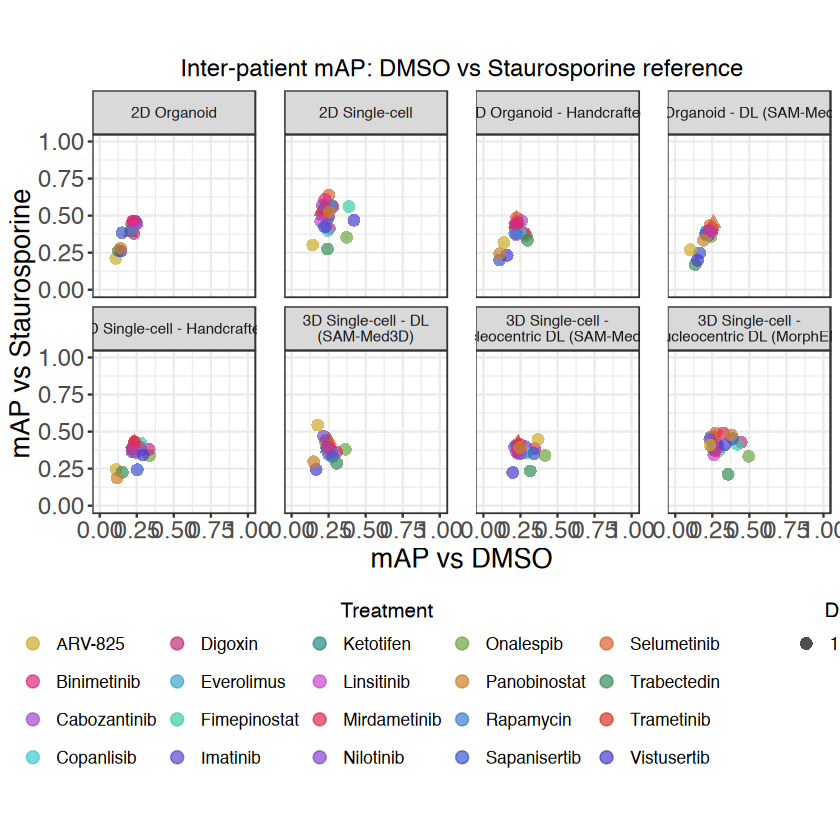

In [4]:
# DMSO mAP vs positive-control mAP, one panel per profile type
for (reference_group in names(positive_controls)) {
    control <- positive_controls[[reference_group]]
    plot_df <- paired_mAP %>% filter(reference_group == !!reference_group)

    mAP_plot <- (
        ggplot(plot_df, aes(x = dmso_mAP, y = control_mAP, color = Metadata_treatment, shape = Metadata_dose))
        + geom_point(size = 3, alpha = 0.7)
        + scale_color_manual(name = "Treatment", values = custom_treatment_palette,
                              guide = guide_legend(ncol = 6, title.position = "top", title.hjust = 0.5, order = 1))
        + scale_shape_manual(name = "Dose", values = dose_shape_palette,
                              guide = guide_legend(title.position = "top", title.hjust = 0.5, order = 2))
        + facet_wrap(~label, ncol = 4, labeller = label_wrap_gen(width = 30))
        + labs(
            x = "mAP vs DMSO",
            y = paste0("mAP vs ", control),
            title = paste0("Inter-patient mAP: DMSO vs ", control, " reference")
        )
        + theme_bw()
        + plot_theme
        + xlim(0, 1)
        + ylim(0, 1)
    )

    ggsave(
        file.path(figures_dir, paste0("inter_patient_mAP_DMSO_vs_", control, ".png")),
        mAP_plot,
        width = 18,
        height = 12,
        dpi = 600
    )
}

mAP_plot

In [5]:
# Every treatment-dose takes a turn as the reference in notebook 19; collect
# every query vs reference mAP into one table per profile type
heatmap_mAP <- list()
for (i in seq_len(nrow(profile_types))) {
    slug <- profile_types$slug[i]
    file_pattern <- paste0("^", slug, "_inter_patient_mAP_vs_(.*)\\.parquet$")
    reference_groups <- sub(file_pattern, "\\1", list.files(results_dir, pattern = file_pattern))

    for (reference_group in reference_groups) {
        mAP_df <- load_mAP(slug, reference_group)
        mAP_df$reference_group <- reference_group
        mAP_df$slug <- slug
        mAP_df$label <- profile_types$label[i]
        heatmap_mAP[[length(heatmap_mAP) + 1]] <- mAP_df
    }
}
heatmap_mAP <- bind_rows(heatmap_mAP)

head(heatmap_mAP)

Metadata_treatment_dose,mean_average_precision,reference_group,slug,label
<chr>,<dbl>,<chr>,<chr>,<chr>
Trametinib_1,0.7789123,ARV-825_1,2D_organoid,2D Organoid
Staurosporine_10,0.8595362,ARV-825_1,2D_organoid,2D Organoid
Onalespib_1,0.7889369,ARV-825_1,2D_organoid,2D Organoid
DMSO_1,0.9303244,ARV-825_1,2D_organoid,2D Organoid
Everolimus_1,0.7817663,ARV-825_1,2D_organoid,2D Organoid
Imatinib_1,0.7903602,ARV-825_1,2D_organoid,2D Organoid


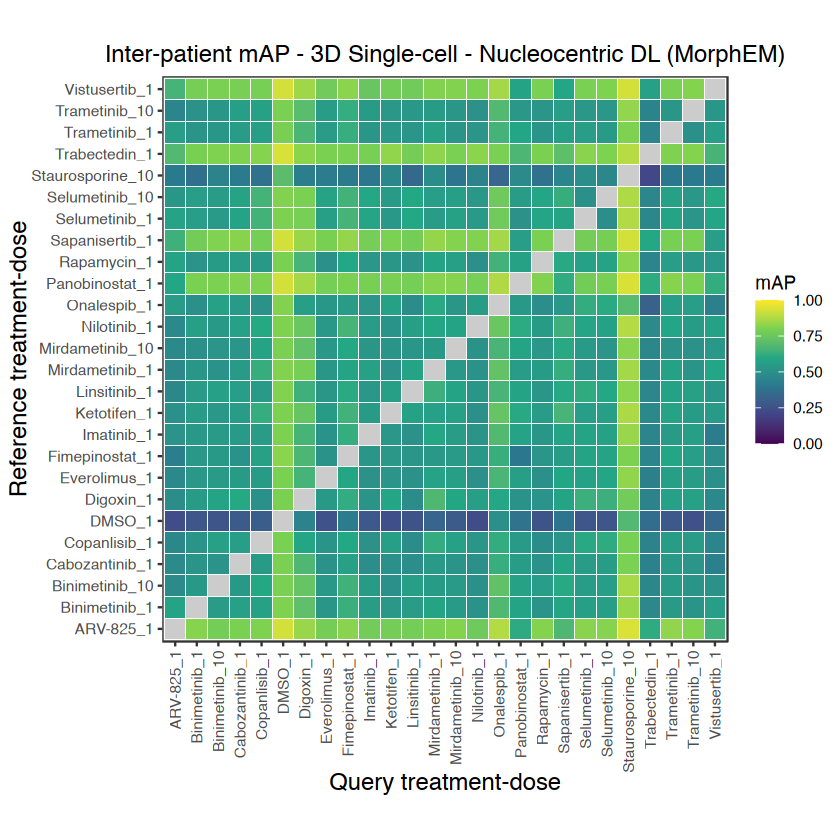

In [6]:
# Query vs reference mAP heatmap; a treatment-dose cannot be its own reference,
# so those cells (and any other missing pair) are filled in as NA and grayed out
make_mAP_heatmap <- function(df, title, reference_on_columns) {
    if (reference_on_columns) {
        x_col <- "reference_group"
        y_col <- "Metadata_treatment_dose"
        x_label <- "Reference treatment-dose"
        y_label <- "Query treatment-dose"
    } else {
        x_col <- "Metadata_treatment_dose"
        y_col <- "reference_group"
        x_label <- "Query treatment-dose"
        y_label <- "Reference treatment-dose"
    }

    (
        ggplot(df, aes(x = .data[[x_col]], y = .data[[y_col]], fill = mean_average_precision))
        + geom_tile(color = "white")
        + scale_fill_viridis_c(name = "mAP", limits = c(0, 1), na.value = "grey80")
        + labs(x = x_label, y = y_label, title = title)
        + theme_bw()
        + theme(
            aspect.ratio = 1,
            plot.title   = element_text(hjust = 0.5, size = 14),
            axis.title.x = element_text(size = 14),
            axis.title.y = element_text(size = 14),
            axis.text.x  = element_text(size = 9, angle = 90, hjust = 1, vjust = 0.5),
            axis.text.y  = element_text(size = 9),
            panel.grid   = element_blank()
        )
    )
}

# Two heatmaps per profile type: reference on the columns, then on the rows
for (i in seq_len(nrow(profile_types))) {
    slug <- profile_types$slug[i]
    label <- profile_types$label[i]

    # Same treatment-dose order on both axes, with every query x reference pair
    plot_df <- heatmap_mAP %>% filter(slug == !!slug)
    treatment_doses <- sort(union(plot_df$Metadata_treatment_dose, plot_df$reference_group))
    plot_df <- plot_df %>%
        mutate(
            Metadata_treatment_dose = factor(Metadata_treatment_dose, levels = treatment_doses),
            reference_group = factor(reference_group, levels = treatment_doses)
        ) %>%
        complete(Metadata_treatment_dose, reference_group)

    for (reference_on_columns in c(TRUE, FALSE)) {
        orientation <- if (reference_on_columns) "reference_columns" else "reference_rows"
        heatmap_plot <- make_mAP_heatmap(
            plot_df,
            paste0("Inter-patient mAP - ", label),
            reference_on_columns
        )
        ggsave(
            file.path(heatmap_figures_dir, paste0(slug, "_inter_patient_mAP_heatmap_", orientation, ".png")),
            heatmap_plot,
            width = 10,
            height = 10,
            dpi = 600
        )
    }
}

heatmap_plot